# Análisis de cohortes

In [1]:
# Importas librerías

import pandas as pd

productos = pd.read_csv('00_Datasets/productos_final.csv', parse_dates = ['Fecha'])
productos.head()

,ID_Cliente,Fecha,ID_Transaccion,Categoria_Producto,Producto,Coste_Unitario,Cantidad,Precio_Unitario
0,1,2023-01-21,3442,0H2,6OUVC,7.64,4.0,10.50
1,1,2023-01-21,3442,N8U,CEBU8,4.57,4.0,5.79
2,2,2023-03-24,14177,TVL,2SLS0,4.60,3.0,7.77
3,2,2023-06-19,30451,F9B,GZ6VU,9.04,3.0,15.00
4,3,2023-01-01,90,LPF,Y1M2E,3.37,4.0,4.08


In [2]:
# Creamos la variable Total_Venta como producto de Cantidad y Precio Unitario
productos ['Total_Venta'] = productos ['Cantidad'] * productos ['Precio_Unitario']

In [3]:
productos.head()

,ID_Cliente,Fecha,ID_Transaccion,Categoria_Producto,Producto,Coste_Unitario,Cantidad,Precio_Unitario,Total_Venta
0,1,2023-01-21,3442,0H2,6OUVC,7.64,4.0,10.50,42.00
1,1,2023-01-21,3442,N8U,CEBU8,4.57,4.0,5.79,23.16
2,2,2023-03-24,14177,TVL,2SLS0,4.60,3.0,7.77,23.31
3,2,2023-06-19,30451,F9B,GZ6VU,9.04,3.0,15.00,45.00
4,3,2023-01-01,90,LPF,Y1M2E,3.37,4.0,4.08,16.32


**1. Creación de una nueva columna que contiene solo el mes y el año de cada transacción**

In [4]:
# Crear columna mes transacción
productos['MesTransaccion'] = productos['Fecha'].dt.to_period('M')

# Revisamos primeras filas
productos[['ID_Cliente', 'Fecha', 'MesTransaccion']]

,ID_Cliente,Fecha,MesTransaccion
0,1,2023-01-21,2023-01
1,1,2023-01-21,2023-01
2,2,2023-03-24,2023-03
3,2,2023-06-19,2023-06
4,3,2023-01-01,2023-01
...,...,...,...
78261,7139,2023-11-30,2023-11
78262,3056,2023-10-17,2023-10
78263,12790,2023-06-04,2023-06
78264,5624,2023-10-03,2023-10


In [5]:
# Revisamos que tenemos el mismo número de clientes
productos.ID_Cliente.nunique()

20688

In [6]:
# Vista ordenada de los datos por Cliente y MesTransaccion
productos.sort_values(by = ['ID_Cliente', 'MesTransaccion']).head(20)

,ID_Cliente,Fecha,ID_Transaccion,Categoria_Producto,Producto,Coste_Unitario,Cantidad,Precio_Unitario,Total_Venta,MesTransaccion
0,1,2023-01-21,3442,0H2,6OUVC,7.64,4.0,10.50,42.00,2023-01
1,1,2023-01-21,3442,N8U,CEBU8,4.57,4.0,5.79,23.16,2023-01
2,2,2023-03-24,14177,TVL,2SLS0,4.60,3.0,7.77,23.31,2023-03
3,2,2023-06-19,30451,F9B,GZ6VU,9.04,3.0,15.00,45.00,2023-06
4,3,2023-01-01,90,LPF,Y1M2E,3.37,4.0,4.08,16.32,2023-01
5,3,2023-01-01,90,TW8,WHV3G,1.15,3.0,1.38,4.14,2023-01
6,3,2023-01-01,90,TW8,WALAE,0.89,3.0,1.38,4.14,2023-01
7,4,2023-07-11,34042,69B,APEJQ,3.48,5.0,6.69,33.45,2023-07
8,4,2023-11-09,54618,YMJ,QR49F,5.31,4.0,7.37,29.48,2023-11
9,4,2023-11-09,54618,29A,RBNO8,5.67,4.0,8.65,34.60,2023-11


In [8]:
# Agrupación de datos por cliente y aplicar la agregacion por la variable Mes Transaccion
productos.groupby('ID_Cliente')['MesTransaccion'].agg('min')

ID_Cliente
1        2023-01
2        2023-03
3        2023-01
4        2023-07
5        2023-02
          ...   
22621    2023-12
22622    2023-12
22623    2023-12
22624    2023-12
22625    2023-12
Name: MesTransaccion, Length: 20688, dtype: period[M]

In [9]:
# Como no queremos reducir las dimensiones de nuestro DF tendremos que usar otro método:
productos.groupby('ID_Cliente')['MesTransaccion'].transform('min')

0        2023-01
1        2023-01
2        2023-03
3        2023-03
4        2023-01
          ...   
78261    2023-11
78262    2023-10
78263    2023-06
78264    2023-10
78265    2023-08
Name: MesTransaccion, Length: 78266, dtype: period[M]

**2.Añadir el mes de cohorte**

El mes en que se hace la primera variable

In [10]:
# Calcular la nueva variable
productos['MesCohorte'] = productos.groupby('ID_Cliente')['MesTransaccion'].transform('min')

In [11]:
# Sacamos una vista ordenada de los datos por Cliente y MesTransacción
productos.sort_values(by=['ID_Cliente','MesTransaccion']).head(20) 

,ID_Cliente,Fecha,ID_Transaccion,Categoria_Producto,Producto,Coste_Unitario,Cantidad,Precio_Unitario,Total_Venta,MesTransaccion,MesCohorte
0,1,2023-01-21,3442,0H2,6OUVC,7.64,4.0,10.50,42.00,2023-01,2023-01
1,1,2023-01-21,3442,N8U,CEBU8,4.57,4.0,5.79,23.16,2023-01,2023-01
2,2,2023-03-24,14177,TVL,2SLS0,4.60,3.0,7.77,23.31,2023-03,2023-03
3,2,2023-06-19,30451,F9B,GZ6VU,9.04,3.0,15.00,45.00,2023-06,2023-03
4,3,2023-01-01,90,LPF,Y1M2E,3.37,4.0,4.08,16.32,2023-01,2023-01
5,3,2023-01-01,90,TW8,WHV3G,1.15,3.0,1.38,4.14,2023-01,2023-01
6,3,2023-01-01,90,TW8,WALAE,0.89,3.0,1.38,4.14,2023-01,2023-01
7,4,2023-07-11,34042,69B,APEJQ,3.48,5.0,6.69,33.45,2023-07,2023-07
8,4,2023-11-09,54618,YMJ,QR49F,5.31,4.0,7.37,29.48,2023-11,2023-07
9,4,2023-11-09,54618,29A,RBNO8,5.67,4.0,8.65,34.60,2023-11,2023-07


**3.Eliminar los registros de cohortes que no están completas**

Al trabajar con las ventanas de 6 meses, no nos valen desde la de agosto en adelante

In [12]:
# Creación de una nueva tabla a la que le asignamos los datos filtrados
resultados = productos[productos['MesCohorte'] <= '2023-07']
resultados

,ID_Cliente,Fecha,ID_Transaccion,Categoria_Producto,Producto,Coste_Unitario,Cantidad,Precio_Unitario,Total_Venta,MesTransaccion,MesCohorte
0,1,2023-01-21,3442,0H2,6OUVC,7.64,4.0,10.50,42.00,2023-01,2023-01
1,1,2023-01-21,3442,N8U,CEBU8,4.57,4.0,5.79,23.16,2023-01,2023-01
2,2,2023-03-24,14177,TVL,2SLS0,4.60,3.0,7.77,23.31,2023-03,2023-03
3,2,2023-06-19,30451,F9B,GZ6VU,9.04,3.0,15.00,45.00,2023-06,2023-03
4,3,2023-01-01,90,LPF,Y1M2E,3.37,4.0,4.08,16.32,2023-01,2023-01
...,...,...,...,...,...,...,...,...,...,...,...
78255,2494,2023-07-27,36500,FU5,3ZY0H,3.34,3.0,4.96,14.88,2023-07,2023-07
78257,3527,2023-04-28,20425,FEW,WG7HI,4.11,3.0,5.18,15.54,2023-04,2023-04
78258,5063,2023-03-13,11915,29A,PO1N6,3.00,10.0,4.96,49.60,2023-03,2023-03
78259,17354,2023-06-29,32041,01F,RVG1H,1.47,3.0,1.68,5.04,2023-06,2023-06


In [13]:
resultados.info()

<class 'pandas.DataFrame'>
Index: 61497 entries, 0 to 78263
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   ID_Cliente          61497 non-null  int64         
 1   Fecha               61497 non-null  datetime64[us]
 2   ID_Transaccion      61497 non-null  int64         
 3   Categoria_Producto  61497 non-null  str           
 4   Producto            61497 non-null  str           
 5   Coste_Unitario      61497 non-null  float64       
 6   Cantidad            61497 non-null  float64       
 7   Precio_Unitario     61497 non-null  float64       
 8   Total_Venta         61497 non-null  float64       
 9   MesTransaccion      61497 non-null  period[M]     
 10  MesCohorte          61497 non-null  period[M]     
dtypes: datetime64[us](1), float64(4), int64(2), period[M](2), str(2)
memory usage: 5.6 MB


**4.Transformar las variables Mes a Datetime**

Permite trabajar mejor los desplazamientos

In [14]:
#pd.to_datetime(resultados['MesTransaccion'], format = '%Y-%m')

In [15]:
# Hacemos una copia de la tabla para no machacar la original y hacemos la transformación de Mes Transaccion y MesCohorte a otra variable puente, como tipo cadena
resultados = resultados.copy()

resultados['MesTransaccion'] = pd.to_datetime(resultados['MesTransaccion'].astype(str), format = '%Y-%m')
resultados['MesCohorte'] = pd.to_datetime(resultados['MesCohorte'].astype(str), format = '%Y-%m')

In [16]:
resultados.info()

<class 'pandas.DataFrame'>
Index: 61497 entries, 0 to 78263
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   ID_Cliente          61497 non-null  int64         
 1   Fecha               61497 non-null  datetime64[us]
 2   ID_Transaccion      61497 non-null  int64         
 3   Categoria_Producto  61497 non-null  str           
 4   Producto            61497 non-null  str           
 5   Coste_Unitario      61497 non-null  float64       
 6   Cantidad            61497 non-null  float64       
 7   Precio_Unitario     61497 non-null  float64       
 8   Total_Venta         61497 non-null  float64       
 9   MesTransaccion      61497 non-null  datetime64[us]
 10  MesCohorte          61497 non-null  datetime64[us]
dtypes: datetime64[us](3), float64(4), int64(2), str(2)
memory usage: 5.6 MB


Vemos que ya ha cambiado la tipología de las variables MesTransaccion y MesCohorte

**Eliminar los registros que no entran en el análisis**

Teniendo presente que la cohorte dura 6 meses, eliminamos aquellos cuyo MesTransaccion sea superior al MesCohorte 5

In [17]:
resultados_filtrados = resultados[resultados['MesTransaccion'] <= resultados['MesCohorte'] + pd.DateOffset(months = 5)]
resultados_filtrados

,ID_Cliente,Fecha,ID_Transaccion,Categoria_Producto,Producto,Coste_Unitario,Cantidad,Precio_Unitario,Total_Venta,MesTransaccion,MesCohorte
0,1,2023-01-21,3442,0H2,6OUVC,7.64,4.0,10.50,42.00,2023-01-01,2023-01-01
1,1,2023-01-21,3442,N8U,CEBU8,4.57,4.0,5.79,23.16,2023-01-01,2023-01-01
2,2,2023-03-24,14177,TVL,2SLS0,4.60,3.0,7.77,23.31,2023-03-01,2023-03-01
3,2,2023-06-19,30451,F9B,GZ6VU,9.04,3.0,15.00,45.00,2023-06-01,2023-03-01
4,3,2023-01-01,90,LPF,Y1M2E,3.37,4.0,4.08,16.32,2023-01-01,2023-01-01
...,...,...,...,...,...,...,...,...,...,...,...
78255,2494,2023-07-27,36500,FU5,3ZY0H,3.34,3.0,4.96,14.88,2023-07-01,2023-07-01
78257,3527,2023-04-28,20425,FEW,WG7HI,4.11,3.0,5.18,15.54,2023-04-01,2023-04-01
78258,5063,2023-03-13,11915,29A,PO1N6,3.00,10.0,4.96,49.60,2023-03-01,2023-03-01
78259,17354,2023-06-29,32041,01F,RVG1H,1.47,3.0,1.68,5.04,2023-06-01,2023-06-01


Vemos que las filas se han reducido y este será el dataset que nos servirá de base para los posteriores análisis.

In [18]:
resultados_filtrados.info()

<class 'pandas.DataFrame'>
Index: 54405 entries, 0 to 78263
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   ID_Cliente          54405 non-null  int64         
 1   Fecha               54405 non-null  datetime64[us]
 2   ID_Transaccion      54405 non-null  int64         
 3   Categoria_Producto  54405 non-null  str           
 4   Producto            54405 non-null  str           
 5   Coste_Unitario      54405 non-null  float64       
 6   Cantidad            54405 non-null  float64       
 7   Precio_Unitario     54405 non-null  float64       
 8   Total_Venta         54405 non-null  float64       
 9   MesTransaccion      54405 non-null  datetime64[us]
 10  MesCohorte          54405 non-null  datetime64[us]
dtypes: datetime64[us](3), float64(4), int64(2), str(2)
memory usage: 5.0 MB


**5.Creación de variable para medir el tiempo de vida del cliente**

In [19]:
# Crear la variable del mes desde el punto de vista del cliente
resultados_filtrados =  resultados_filtrados.copy()

# paso 1: Crear columnas temporales tipo Period [M]
mes_transaccion_period = resultados_filtrados['MesTransaccion'].dt.to_period('M')
mes_cohorte_period = resultados_filtrados['MesCohorte'].dt.to_period('M')

# paso 2: calcular la diferencia en meses de columnas temporales
diferencia_meses = mes_transaccion_period - mes_cohorte_period

# paso 3: crear la nueva columna MesCliente con la diferencia calculada
resultados_filtrados.loc[:, 'MesCliente'] = 'M' + diferencia_meses.apply(lambda x: str(x.n+1))

# Mostrar resultado

resultados_filtrados


,ID_Cliente,Fecha,ID_Transaccion,Categoria_Producto,Producto,Coste_Unitario,Cantidad,Precio_Unitario,Total_Venta,MesTransaccion,MesCohorte,MesCliente
0,1,2023-01-21,3442,0H2,6OUVC,7.64,4.0,10.50,42.00,2023-01-01,2023-01-01,M1
1,1,2023-01-21,3442,N8U,CEBU8,4.57,4.0,5.79,23.16,2023-01-01,2023-01-01,M1
2,2,2023-03-24,14177,TVL,2SLS0,4.60,3.0,7.77,23.31,2023-03-01,2023-03-01,M1
3,2,2023-06-19,30451,F9B,GZ6VU,9.04,3.0,15.00,45.00,2023-06-01,2023-03-01,M4
4,3,2023-01-01,90,LPF,Y1M2E,3.37,4.0,4.08,16.32,2023-01-01,2023-01-01,M1
...,...,...,...,...,...,...,...,...,...,...,...,...
78255,2494,2023-07-27,36500,FU5,3ZY0H,3.34,3.0,4.96,14.88,2023-07-01,2023-07-01,M1
78257,3527,2023-04-28,20425,FEW,WG7HI,4.11,3.0,5.18,15.54,2023-04-01,2023-04-01,M1
78258,5063,2023-03-13,11915,29A,PO1N6,3.00,10.0,4.96,49.60,2023-03-01,2023-03-01,M1
78259,17354,2023-06-29,32041,01F,RVG1H,1.47,3.0,1.68,5.04,2023-06-01,2023-06-01,M1


**6.Creación de la tabla de cohortes por meses naturales**

In [20]:
# Creación de tabla pivotada
cohorte_final_natural = pd.pivot_table(
    resultados_filtrados,
    index = 'MesCohorte',
    columns = 'MesTransaccion',
    values = 'ID_Cliente',
    aggfunc = 'nunique' # Cuenta clientes únicos por cada cohorte y mes
).fillna(0).astype(int) # Rellenar NaN con 0 y convertir a enteros

cohorte_final_natural

MesTransaccion,2023-01-01,2023-02-01,2023-03-01,2023-04-01,2023-05-01,2023-06-01,2023-07-01,2023-08-01,2023-09-01,2023-10-01,2023-11-01,2023-12-01
MesCohorte,,,,,,,,,,,,
2023-01-01,3114,1011,778,458,189,134,0,0,0,0,0,0
2023-02-01,0,2051,408,241,121,72,53,0,0,0,0,0
2023-03-01,0,0,2160,390,303,261,206,213,0,0,0,0
2023-04-01,0,0,0,2079,403,329,265,295,281,0,0,0
2023-05-01,0,0,0,0,2334,434,380,311,373,361,0,0
2023-06-01,0,0,0,0,0,1461,210,203,212,206,205,0
2023-07-01,0,0,0,0,0,0,1168,147,156,162,154,170


**7.Creación de la tabla de cohortes por mes del cliente (el tiempo de vida de cada Cohorte desde su inicio)**

In [21]:
# Crear tabla pivotada a nivel de mes cliente

tabla_cohortes = pd.pivot_table(
    resultados_filtrados,
    index = 'MesCohorte',
    columns = 'MesCliente',
    values = 'ID_Cliente',
    aggfunc = 'nunique' 
).fillna(0).astype(int) 
tabla_cohortes

MesCliente,M1,M2,M3,M4,M5,M6
MesCohorte,,,,,,
2023-01-01,3114,1011,778,458,189,134
2023-02-01,2051,408,241,121,72,53
2023-03-01,2160,390,303,261,206,213
2023-04-01,2079,403,329,265,295,281
2023-05-01,2334,434,380,311,373,361
2023-06-01,1461,210,203,212,206,205
2023-07-01,1168,147,156,162,154,170


Aplicar formato a la tabla

In [22]:
# Tabla de cohortes formateada
tabla_cohortes_f = tabla_cohortes.style.background_gradient(cmap = 'Blues', axis = None)
tabla_cohortes_f 

MesCliente,M1,M2,M3,M4,M5,M6
MesCohorte,,,,,,
2023-01-01 00:00:00,3114,1011,778,458,189,134
2023-02-01 00:00:00,2051,408,241,121,72,53
2023-03-01 00:00:00,2160,390,303,261,206,213
2023-04-01 00:00:00,2079,403,329,265,295,281
2023-05-01 00:00:00,2334,434,380,311,373,361
2023-06-01 00:00:00,1461,210,203,212,206,205
2023-07-01 00:00:00,1168,147,156,162,154,170


**8.Calcular la tasa de retención**

In [28]:
# Calcular tabla de retencion
tabla_retencion = tabla_cohortes.div(tabla_cohortes['M1'], axis =0) * 100

# Para redondear
tabla_retencion = tabla_retencion.round(1)
tabla_retencion

MesCliente,M1,M2,M3,M4,M5,M6
MesCohorte,,,,,,
2023-01-01,100.0,32.5,25.0,14.7,6.1,4.3
2023-02-01,100.0,19.9,11.8,5.9,3.5,2.6
2023-03-01,100.0,18.1,14.0,12.1,9.5,9.9
2023-04-01,100.0,19.4,15.8,12.7,14.2,13.5
2023-05-01,100.0,18.6,16.3,13.3,16.0,15.5
2023-06-01,100.0,14.4,13.9,14.5,14.1,14.0
2023-07-01,100.0,12.6,13.4,13.9,13.2,14.6


In [30]:
# Aplicamos formato
tabla_retencion_f = tabla_retencion.style.format("{:.1f}").background_gradient(cmap = 'Blues', axis = None)
tabla_retencion_f

MesCliente,M1,M2,M3,M4,M5,M6
MesCohorte,,,,,,
2023-01-01 00:00:00,100.0,32.5,25.0,14.7,6.1,4.3
2023-02-01 00:00:00,100.0,19.9,11.8,5.9,3.5,2.6
2023-03-01 00:00:00,100.0,18.1,14.0,12.1,9.5,9.9
2023-04-01 00:00:00,100.0,19.4,15.8,12.7,14.2,13.5
2023-05-01 00:00:00,100.0,18.6,16.3,13.3,16.0,15.5
2023-06-01 00:00:00,100.0,14.4,13.9,14.5,14.1,14.0
2023-07-01 00:00:00,100.0,12.6,13.4,13.9,13.2,14.6


**Consultas con la tabla de retención**

In [31]:
# Tasa de retención media para cada cohorte
tabla_retencion.mean()

MesCliente
M1    100.000000
M2     19.357143
M3     15.742857
M4     12.442857
M5     10.942857
M6     10.628571
dtype: float64

No es correcta ya que promediamos porcentajes de retención para cada cohorte sin considerar el tamaño original de la misma.
Debemos calcular la retención promedio ponderada para cada cohorte, desde la tabla de absolutos.

In [34]:
# Sumar el total de clientes en M1 para todas las cohortes
total_inicial = tabla_cohortes['M1'].sum()

# Suamr el total de clientes retenidos en cada mes
total_retenidos = tabla_cohortes.sum()

# Calcular la tasa media
tasa_media = total_retenidos / total_inicial
tasa_media

MesCliente
M1    1.000000
M2    0.209021
M3    0.166353
M4    0.124591
M5    0.104058
M6    0.098629
dtype: float64

<Axes: xlabel='MesCliente'>

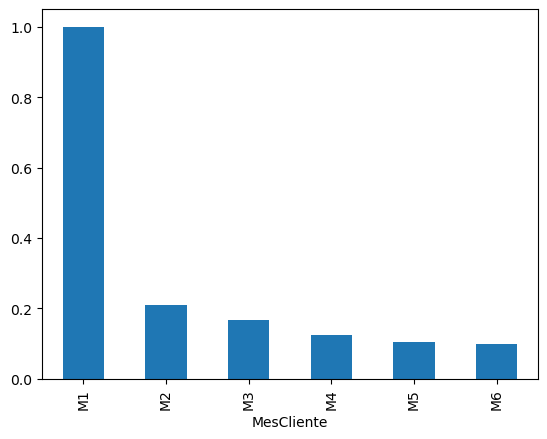

In [35]:
# Graficamos
tasa_media.plot(kind = 'bar')

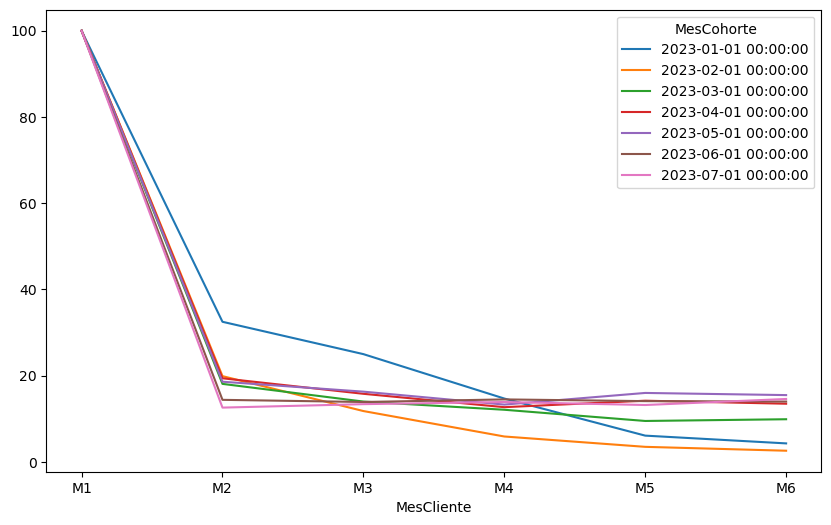

In [36]:
# Variación de la cantidad de clientes activos mes a mes para cada cohorte
tabla_retencion.T.plot(kind = 'line', figsize =(10,6));

In [38]:
# Calcular el total de clientes iniciales en todas las cohortes
total_inicial_global = tabla_cohortes['M1'].sum()

# Calcular el total de clientes retenidos en el último mes (M6)
total_retenidos_final = tabla_cohortes['M6'].sum()

# Calcular la tasa de retención global usando sólo el último mes
tasa_retencion_global = total_retenidos_final / total_inicial_global
tasa_retencion_global

np.float64(0.09862880211596019)

**Código Cohortes Unificado**

In [ ]:
"""# Crear columna mes transacción
productos['MesTransaccion'] = productos['Fecha'].dt.to_period('M')

# Calcular el mes de cohorte
productos['MesCohorte'] = productos.groupby('ID_Cliente')['MesTransaccion'].transform('min')

# Eliminar registros de cohortes no completos
resultados = productos[productos['MesCohorte'] <= '2023-07']

# Transformar las variables Mes a datetime
resultados = resultados.copy()
resultados['MesTransaccion'] = pd.to_datetime(resultados['MesTransaccion'].astype(str), format = '%Y-%m')
resultados['MesCohorte'] = pd.to_datetime(resultados['MesCohorte'].astype(str), format = '%Y-%m')

# Eliminar registros que no entran en el mes de cohorte de estudio
resultados_filtrados = resultados[resultados['MesTransaccion'] <= resultados['MesCohorte'] + pd.DateOffset(months = 5)]

# Crear la variable del mes desde el punto de vista del cliente
resultados_filtrados =  resultados_filtrados.copy()
#paso 1: Crear columnas temporales tipo Period [M]
mes_transaccion_period = resultados_filtrados['MesTransaccion'].dt.to_period('M')
mes_cohorte_period = resultados_filtrados['MesCohorte'].dt.to_period('M')
# paso 2: calcular la diferencia en meses de columnas temporales
diferencia_meses = mes_transaccion_period - mes_cohorte_period
# paso 3: crear la nueva columna MesCliente con la diferencia calculada
resultados_filtrados.loc[:, 'MesCliente'] = 'M' + diferencia_meses.apply(lambda x: str(x.n+1))


# Crear tabla pivotada a nivel de mes cliente
tabla_cohortes = pd.pivot_table(
    resultados_filtrados,
    index = 'MesCohorte',
    columns = 'MesCliente',
    values = 'ID_Cliente',
    aggfunc = 'nunique' 
).fillna(0).astype(int) 

# Calcular la tabla de retención
tabla_retencion = tabla_cohortes.div(tabla_cohortes['M1'], axis =0) * 100
tabla_retencion = tabla_retencion.round(1)
"""